In [2]:
try:
     from dlroms import*
except:
     !pip install --no-deps git+https://github.com/NicolaRFranco/dlroms.git
     from dlroms import*
import numpy as np
import matplotlib.pyplot as plt
import gdown
clc()

## Ex 1 - **Location and monitoring of aquifers** (Darcy flow)

### Mesh and data download

In [2]:
gdown.download(id = "1cPcWium7XTJqd828r0mxZpaghl6DRfQj", output = "terrain_mesh.xml", quiet = False)
gdown.download(id = "1rhAqgdJWDZthXN2ly3QQGYxfVyxsytoL", output = "terrain_simulations.npz", quiet = False)

mesh = fe.loadmesh("terrain_mesh.xml")
Vh = fe.space(mesh, 'CG', 1)
clc()

dataset = np.load("terrain_simulations.npz")
mu, u = dataset["mu"], dataset["u"]

mu.shape, u.shape

((200, 3), (200, 1577))

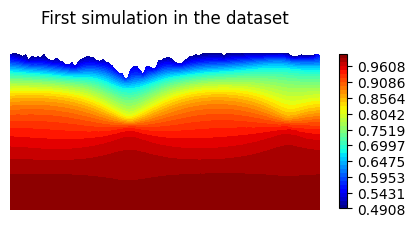

In [3]:
plt.figure(figsize = (5, 5))
fe.plot(u[0], Vh, levels = 40, colorbar = True, shrink = 0.4)
plt.title("First simulation in the dataset\n")
None

### Auxiliary tools

In [4]:
# Aquifer plot
import torch
from dlroms.minns import Interpolate

Dh = fe.space(mesh, 'DG', 0)
clc()

interpolator = Interpolate(mesh, Vh, Dh)
interpolator.to(dv)

def aquifer_plot(u0):
  u0t = u0 if isinstance(u0, torch.Tensor) else dv.tensor(u0)
  acquifer = interpolator((((u0t>0.7)*(u0t<0.85)*1.0)).reshape(1, -1))[0]
  fe.plot(acquifer, Dh, cmap = 'YlOrBr_r')
  plt.title("Acquifer profile\n")

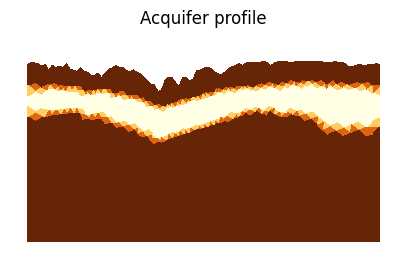

In [5]:
# Usage example
plt.figure(figsize = (5, 5))
aquifer_plot(u[0])

In [6]:
# Aquifer maximum thickness computation
def aquifer_maxthickness(u0):
  band = fe.dofs(Vh)[(u0>0.7)*(u0<0.85)]
  x0, h = np.linspace(0, 1, 100), mesh.hmax()
  bools = (band[:, 0].reshape(-1, 1)<=x0.reshape(1, -1)+h/2)*(band[:, 0].reshape(-1, 1)>=x0.reshape(1, -1)-h/2)
  y_at_x0 = band[:, 1].reshape(-1, 1)*bools
  ymax_at_x0 = y_at_x0.max(axis = 0)
  y_at_x0[y_at_x0==0] = np.inf
  ymin_at_x0 = y_at_x0.min(axis = 0)
  return (ymax_at_x0-ymin_at_x0).max()

# Usage example
aquifer_maxthickness(u[0])

np.float32(0.115914196)

## Ex 2 - **Damage propagation in a U-bolt** (FKPP)

### Mesh construction and data download

In [25]:
# Mesh definition
points = [np.array([0.0, 0.0])]
def step(z):
  points.append(points[-1] + [z.real, z.imag])
def arch(r, thetas, knots = 30):
  rho = np.abs(r)
  center = points[-1] + [r.real, r.imag]
  th = np.linspace(*thetas, knots)[1:]
  shift = rho*np.exp(1j*th)
  vals = np.stack([center[0] + shift.real, center[1]+shift.imag], axis = 1)
  for v in vals:
    points.append(v)

step(3j)
arch(2, thetas = (np.pi, 0))
step(-3j)
step(-1)
step(3j)
arch(-1, thetas = (0, np.pi))
step(-3j)
step(-1)

points = np.stack(points)

domain = fe.polygon(points)
mesh = fe.mesh(domain, stepsize = 0.05)
Vh = fe.space(mesh, 'CG', 1)
clc()

In [3]:
# Data download
gdown.download(id = "1ehojde4rL-8-zoyiKikes3e76CpPvJzC", quiet = False, output = "u-bolt.npz")
clc()

data = np.load("u-bolt.npz")
mu, u = dv.tensor(data['mu'], data['u'])

mu.shape, u.shape

(torch.Size([100, 3]), torch.Size([100, 41, 6636]))

### Auxiliary tools

In [27]:
# Damage plot with modified colors

from matplotlib.colors import ListedColormap
import matplotlib as mpl
jet = mpl.colormaps['jet']
jet_colors = jet(np.linspace(0, 1, 256))
def modify_jet_to_gray(jet_colors):
    new_colors = jet_colors.copy()
    gray_vals = np.linspace(0.3, 0.7, 85)
    for i in range(85):
        new_colors[i, 0:3] = gray_vals[i]
    return ListedColormap(new_colors)
gray_jet = modify_jet_to_gray(jet_colors)

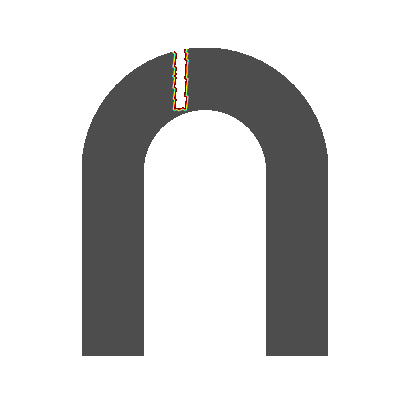

In [28]:
# Usage example
fe.animate(u[0], Vh, cmap = gray_jet) # 1st simulation in the dataset

In [29]:
# Auxiliary functions for pointwise evaluations (needed for Task (iii))
from dlroms.minns import Evaluate
x0 = np.array([[0.5, 3]])
evaluate = Evaluate(mesh, Vh, x0)
evaluate.to(dv)

# Usage example
u0 = u[0]
damage_atx0 = evaluate(u0) # returns a tensor of shape (Nt, 1), corresponding to the values of u0 at x0 over time
damage_atx0.shape

torch.Size([41, 1])

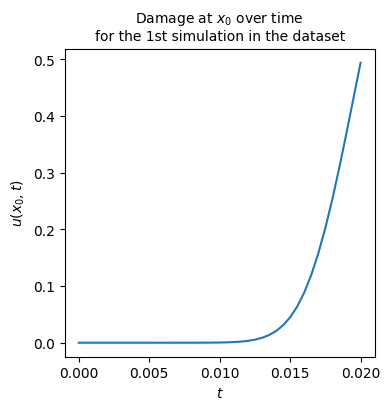

In [30]:
nt = len(u0)
T = (nt-1)*5e-4

time_grid = np.linspace(0, T, nt)

plt.figure(figsize = (4, 4))
plt.plot(time_grid, damage_atx0.cpu().numpy())
plt.title("Damage at $x_0$ over time\nfor the 1st simulation in the dataset", fontsize = 10)
plt.xlabel("$t$")
plt.ylabel("$u(x_0,t)$")
None

In [14]:
# Measurements available (corresponding to "evaluate(u)" for some unknown u!)
gdown.download(id = "16htWP91l5tpgK3ZYqjK-GHvVpW7lr2a5", quiet = False, output = "damage_measurements.npy")
clc()

damage_measurements = np.load("damage_measurements.npy")
damage_measurements.shape

(41, 1)

## Ex 3 - **Sidewalk degradation** (Linear elasticity)

### Mesh construction and data download

In [18]:
mesh = fe.unitsquaremesh(40, 40)
Vh = fe.space(mesh, 'CG', 1, vector_valued = True)
clc()

gdown.download(id = "1jMzgW3fe0A1BRiX1O4jH0T7GGUqnqVar", output = "sidewalk.npz")
clc()

data = np.load("sidewalk.npz")
mu, u = data['mu'], data['u']

mu.shape, u.shape

((100, 2), (100, 51, 3362))

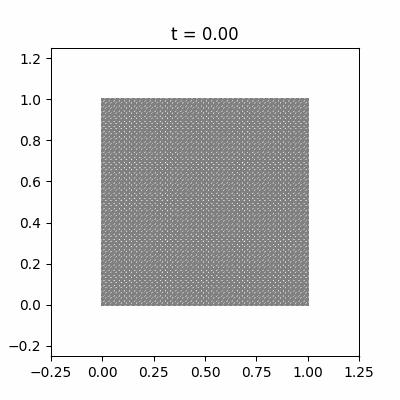

In [19]:
# Visualization of the first simulation in the dataset
fe.animate(u[0], Vh, warp = True, axis = [-0.25, 1.25, -0.25, 1.25], T = 5, dt = 0.1)

### Auxiliary tools

In [20]:
# Computation of the average vertical deformation at the top boundary

ns, nt, nh = u.shape
indexes = 1-fe.dofs(Vh)[:, 1]<1e-12   # indexes of the dofs located at the top edge
tindex = np.arange(0, 51, 10)         # indexes of the times t_1, ..., t_q

def Q(u):
  """Given a space-time solution u, returns [Q(u,t_1), ..., Q(u, t_q)].
  If multiple solutions are passed, the output is computed batchwise.

  Works both on numpy arrays and torch tensors."""

  U = u.reshape(-1, nt, nh)[:, :, indexes]
  vals = U.reshape(-1, nt, np.sum(indexes)//2, 2)[:, :, :, 1].mean(axis = -1)[:, tindex]
  return vals if len(U)>1 else vals[0]

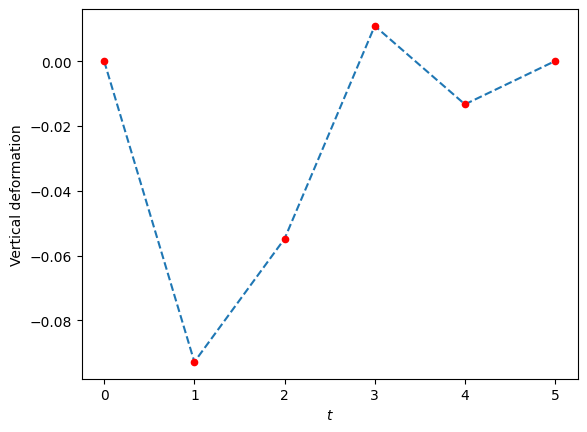

In [21]:
# Usage example
top_vertical_deformation = Q(u[0]) # average vertical deformation at the top for the 1st simulation, computed at the timesteps t1, ..., tq
times = np.linspace(0, 5, nt)

plt.plot(times[tindex], top_vertical_deformation, '--')
plt.plot(times[tindex], top_vertical_deformation, '.', color = 'red', markersize = 9)
plt.xlabel("$t$")
plt.ylabel("Vertical deformation")
None

In [22]:
# Measurements available for Task (iii)
gdown.download(id = "1H51m5HL1RC0PDxnrM-q6YGjJjfbM6cC5", output = "surface_measurements.npy")
clc()

measurements = np.load("surface_measurements.npy")
measurements

array([ 0.01079223, -0.10217915, -0.07301079,  0.00097444, -0.00993845,
        0.00946097])

In [23]:
top_vertical_deformation # Comparison with what the camera would have recorded under the scenario in the 1st simulation, Q(u[0]) computed above as an example

array([ 0.00000000e+00, -9.27910484e-02, -5.47814538e-02,  1.09186950e-02,
       -1.32852061e-02,  8.07099377e-05])